# IN2022_V06: full ADCP record and two candidate eddy visits

A simple first look: load **all rows**, plot the whole record, then extract two broad time windows from `info.md`. These are candidate visits, not confirmed eddy transects; mooring work and other ship activity may remain. Refine the UTC windows after comparing the tracks with your own OceanCurrent inspection. No LATTE fitting or background-current removal is performed here.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
import importlib

# Works from this notebook folder or the repository root.
STUDY_DIR = Path.cwd()
if not (STUDY_DIR / 'inspection_tools.py').is_file():
    STUDY_DIR = STUDY_DIR / 'seacofs_eddy_tilt_analysis/observations/MNF_IN2022_V06_adcp_trawler'
if not (STUDY_DIR / 'inspection_tools.py').is_file():
    raise FileNotFoundError('Run from the notebook folder or the UNSW-PhD repository root.')
sys.path.insert(0, str(STUDY_DIR))
import inspection_tools as inspect
importlib.reload(inspect)

DATA_PATH = Path('/srv/scratch/z5297792/tilt_observation_data/MNF_IN2022_V06_adcp_trawler/MNF_IN2022_V06_adcp_trawler.csv')
# End times are exclusive; the first window includes all of 14–16 July.
WINDOWS = {
    'Visit 1: 14–16 July': ('2022-07-14T00:00:00Z', '2022-07-17T00:00:00Z'),
    'Visit 2: around 24 July': ('2022-07-23T00:00:00Z', '2022-07-26T00:00:00Z'),
}
MIN_ATTENDANCE = None  # Optional plot filter (%); None keeps all attendance values.
VELOCITY_LIMIT = 1.0   # Shared U/V colour limits (m/s).


## Load the whole CSV

This export contains literal `\r\n` sequences. Decode those line breaks before reading. `data` retains every exported row, with shorter column names and UTC timestamps. Both instruments remain separate; no QC meaning is inferred from the blank `Avg QC` field.


In [2]:
data = inspect.load_full_record(DATA_PATH)
print(f'{len(data):,} rows; {data.time.min()} to {data.time.max()}')
display(data.head())
display(data.groupby('instrument').agg(
    rows=('depth', 'size'), start_utc=('time', 'min'), end_utc=('time', 'max'),
    shallowest_m=('depth', 'min'), deepest_m=('depth', 'max'),
))
display(data[['time', 'lat', 'lon', 'depth', 'u', 'v', 'attendance', 'Avg QC']].isna().sum().rename('missing rows'))


195,006 rows; 2022-07-14 05:42:58+00:00 to 2022-07-27 20:50:46+00:00


,Survey,Datafile,time,lat,lon,Project,MARLIN,MARLIN UUID,Averaging Period (sec),U Ship (m/sec),V Ship (m/sec),Bottom Depth,depth,u,v,Avg QC,attendance,instrument
0,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,18.0,-0.108,-0.016,NaN,100,os150nb
1,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,26.0,-0.009,0.000,NaN,100,os150nb
2,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,34.0,0.002,-0.056,NaN,100,os150nb
3,IN2022_V06,in2022_v06_ADCP_pt1_os75nb.nc,2022-07-14 05:43:00+00:00,-26.76499,153.43301,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.60,-1.16,NaN,30.0,-0.004,-0.007,NaN,84,os75nb
4,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:47:58+00:00,-26.76803,153.44934,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.47,-1.12,NaN,18.0,-0.143,0.005,NaN,100,os150nb


,rows,start_utc,end_utc,shallowest_m,deepest_m
instrument,,,,,
os150nb,97257,2022-07-14 05:42:58+00:00,2022-07-27 20:50:46+00:00,17.9,346.0
os75nb,97749,2022-07-14 05:43:00+00:00,2022-07-27 18:00:46+00:00,30.0,750.0


time               0
lat                0
lon                0
depth              0
u                  0
v                  0
attendance         0
Avg QC        195006
Name: missing rows, dtype: int64

## Plot the whole record

Track points are reduced to one position per instrument/time so depth bins do not duplicate the track. Velocity panels show individual time–depth samples, with no interpolation across gaps. All depths are shown. Colour limits clip the displayed colours only; values in `data` are unchanged. An optional attendance threshold affects velocity plots only.


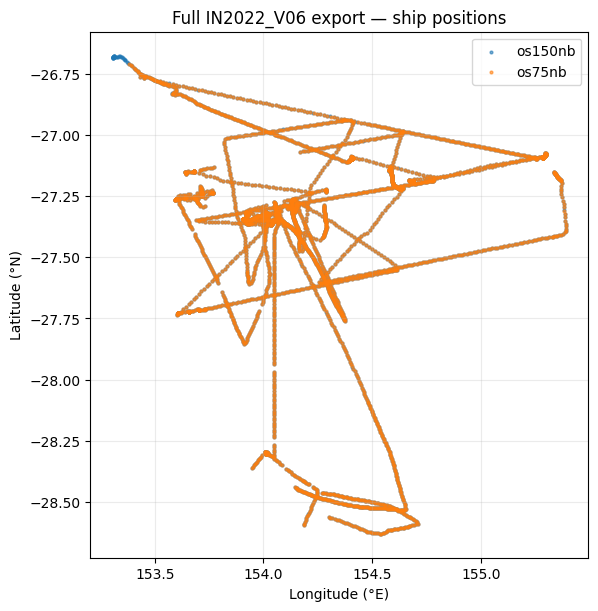

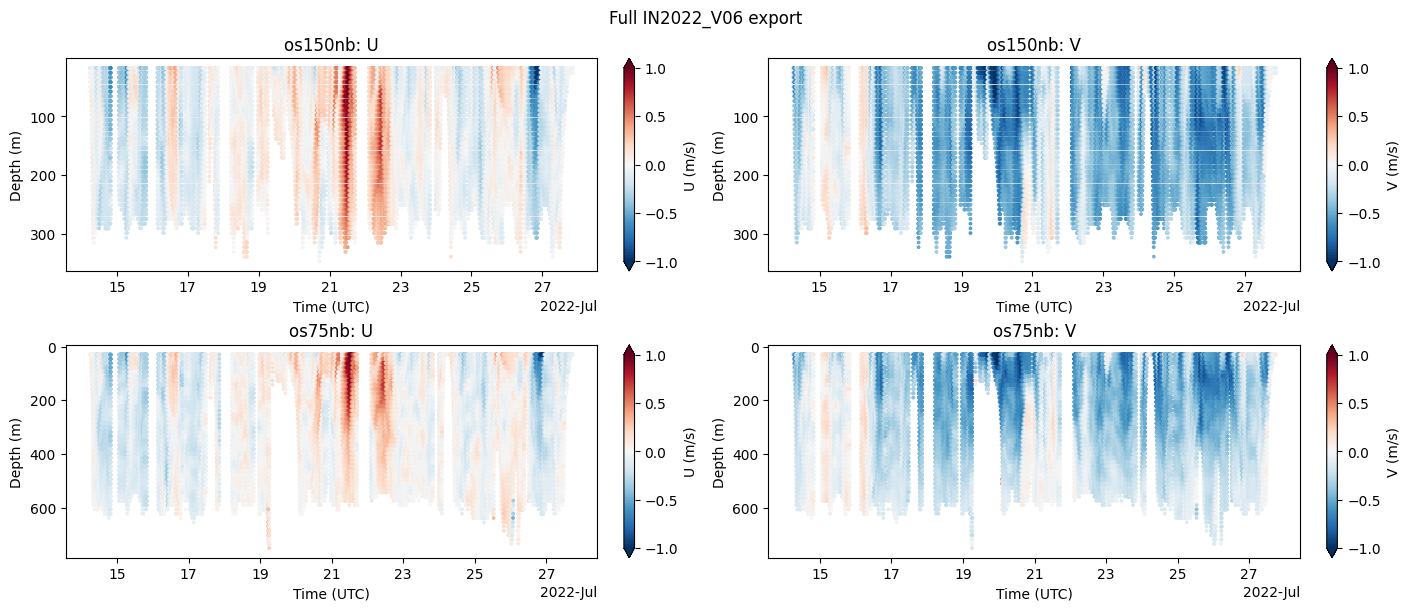

In [3]:
inspect.plot_record(data, 'Full IN2022_V06 export',
                    min_attendance=MIN_ATTENDANCE, velocity_limit=VELOCITY_LIMIT)


## First-pass isolation of the two visits

`sample_1` and `sample_2` contain **all depths and both instruments** inside the editable date windows, including low-attendance rows. The overview below colours each visit over the full ship track. The following plots show each visit separately, making it easier to narrow its start/end times. Date selection alone does not establish a crossing of the eddy centre.


,visit,rows,profiles,start_utc,end_utc,min_lon,max_lon,min_lat,max_lat
0,Visit 1: 14–16 July,40666,1233,2022-07-14 05:42:58+00:00,2022-07-16 23:57:38+00:00,153.43286,155.39103,-27.60460,-26.76496
1,Visit 2: around 24 July,48513,1594,2022-07-23 00:03:41+00:00,2022-07-25 23:55:15+00:00,153.60135,154.61845,-27.75934,-26.93773


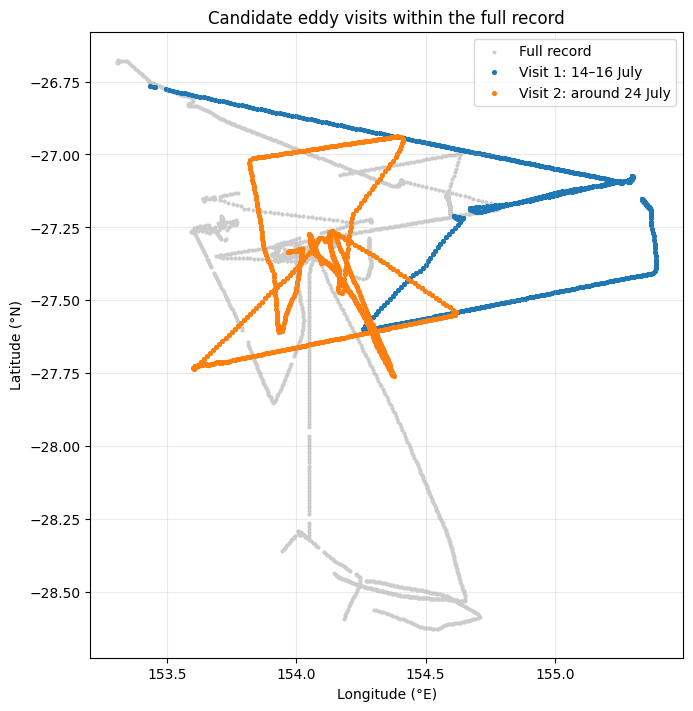

In [4]:
samples = {}
for name, (start, end) in WINDOWS.items():
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    samples[name] = data.loc[(data.time >= start) & (data.time < end)].copy()
sample_1, sample_2 = samples.values()

display(pd.DataFrame([
    dict(visit=name, rows=len(part), profiles=part[['instrument', 'time']].drop_duplicates().shape[0],
         start_utc=part.time.min(), end_utc=part.time.max(),
         min_lon=part.lon.min(), max_lon=part.lon.max(),
         min_lat=part.lat.min(), max_lat=part.lat.max())
    for name, part in samples.items()
]))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
track = data.dropna(subset=['lon', 'lat']).drop_duplicates(['instrument', 'time'])
ax.scatter(track.lon, track.lat, s=3, color='0.8', label='Full record')
for name, part in samples.items():
    positions = part.drop_duplicates(['instrument', 'time'])
    ax.scatter(positions.lon, positions.lat, s=7, label=name)
ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)', title='Candidate eddy visits within the full record')
ax.set_aspect(1 / np.cos(np.deg2rad(track.lat.mean())))
ax.legend()
ax.grid(alpha=0.25)
plt.show()


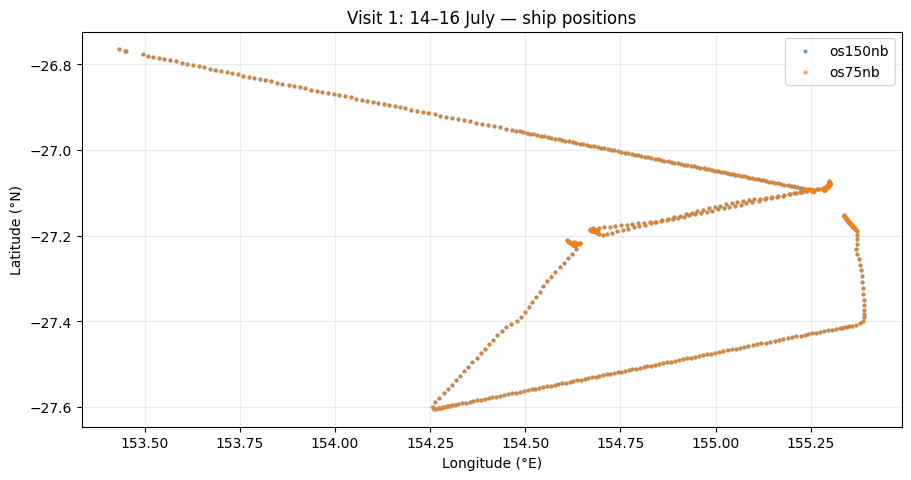

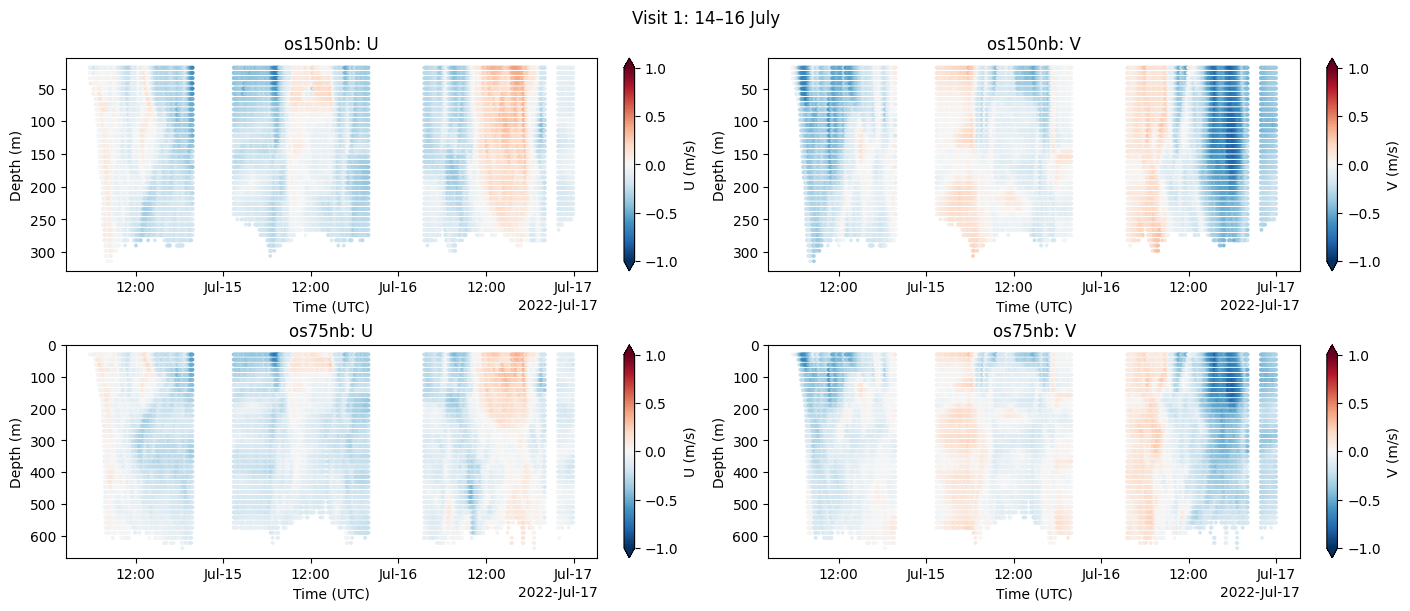

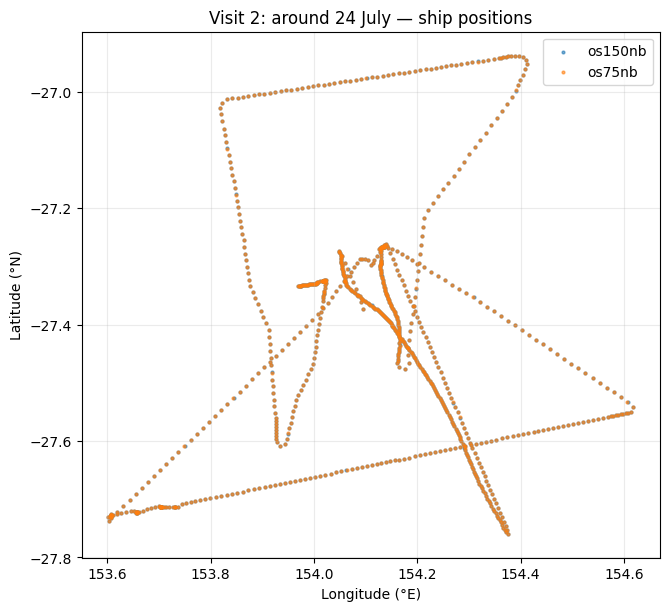

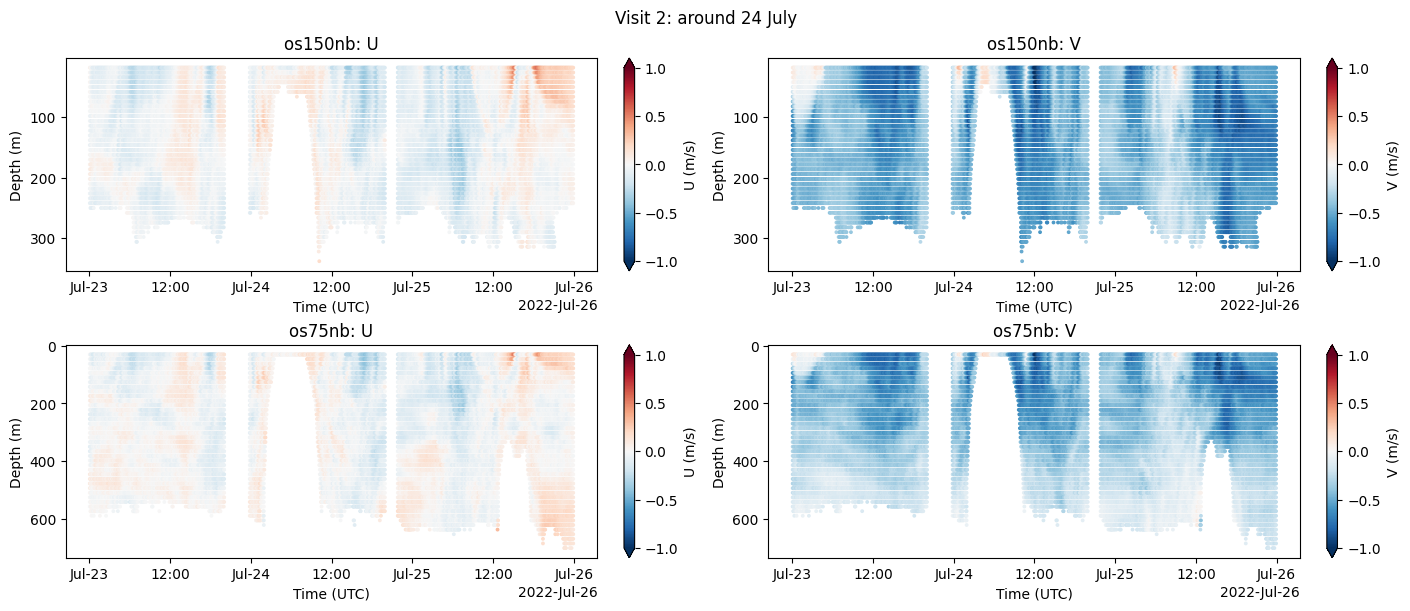

In [5]:
for name, part in samples.items():
    inspect.plot_record(part, name, min_attendance=MIN_ATTENDANCE,
                        velocity_limit=VELOCITY_LIMIT)


Edit `WINDOWS` and rerun the selection and visit plots to trim away unrelated activity. The starting windows are deliberately broad. Use `sample_1` and `sample_2` directly for subsequent analysis, selecting an instrument explicitly when needed, e.g. `sample_1.query("instrument == 'os150nb'")`.


## Choose a time and ADCP window

Choose the UTC centre time and total ADCP window below, then run the next cell. Missing daily OceanCurrent maps are downloaded automatically from AODN and cached beside the ADCP CSV. Later calls reuse these files. Internet access is needed only for missing files.

An exact daily map is used when available; otherwise GSLA and total geostrophic velocity are linearly interpolated between surrounding daily maps. The background is a snapshot at the centre time, not an average over the ADCP window. Source times appear on the plot. All ADCP depths and instruments in the window are returned as `selected`.


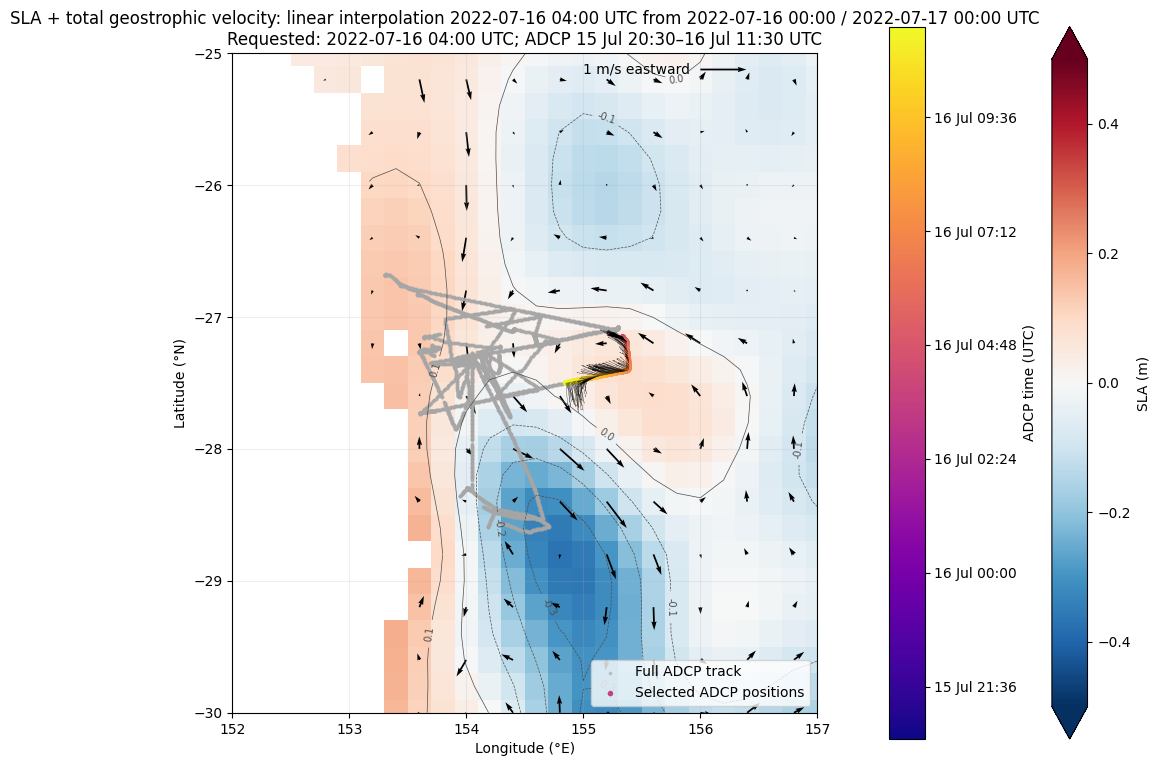

6,657 ADCP rows in [2022-07-15 20:30:00+00:00, 2022-07-16 11:30:00+00:00); linear interpolation 2022-07-16 04:00 UTC from 2022-07-16 00:00 / 2022-07-17 00:00 UTC


In [46]:
TIME_UTC = '2022-07-16T04:00:00Z'
ADCP_WINDOW_HOURS = 15  # Total width: ADCP_WINDOW_HOURS//2 hours either side.
selected = inspect.inspect_time(
    data, DATA_PATH.parent, TIME_UTC, window_hours=ADCP_WINDOW_HOURS, quiv_scale=10, quiv_width=.0005
)

